# Individual Miniproject 2026/27

This miniproject brings together exercises from Weeks 1, 2 and 3. It counts for 50% of the grade for the Methods part of the course.

**Before you start:** make a copy of this notebook in your own Drive (`File` → `Save a copy in Drive`).

**Before you hand in:**
1. Use `Runtime` → `Restart session and run all`, and check that every cell runs.
2. Download the notebook (`File` → `Download` → `Download .ipynb`) and hand in the `.ipynb` file on Canvas, together with your two DataCamp certificates as PDFs.

**Student number:** You can only access the assignment data by inserting your student number in the cell below. The datasets below are individualized per student.

**Grading criteria**: Most of the points below can be scored by simply writing correct Python code and answers. For the more open-ended questions and writing exercises, we also look for critical reflection, engagement with the course, originality, and presentation of visualizations.

| Part | Points |
| --- | --- |
| Week 1, Exercise 1: Python library | 10 |
| Week 1, Exercise 2: DataCamp *Introduction to Python* | 5 |
| Week 2, Exercise 1: DataCamp *Intermediate Python* | 5 |
| Week 2, Exercise 2: Doctor Who | 18 |
| Week 2, Exercise 3: the *Hidden Harbours* campaign | 20 |
| Week 3, Exercise 1: library members | 17 |
| Week 3, Exercise 2: critical reflection | 25 |
| **Total** | **100** |

⚠ **Make sure to carefully read the rules for fraud, plagiarism, and GenAI for this assignment on the [Concepts Canvas page](https://canvas.uva.nl/courses/61929) (4g).**

In [1]:
# Keep and run cell
# IMPORTANT: type your student number between the quotes, then run
# This will create two files: exhihition_posts.csv and library_members.csv
STUDENT_NUMBER = "16831586"

import os, urllib.request
if not os.path.exists('cda_personal.py'):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/goto4711/cdai/main/cda_personal.py', 'cda_personal.py')
from cda_personal import make_my_data
make_my_data(STUDENT_NUMBER)

✅ Your personal data for student number 16831586 are ready: exhibition_posts.csv, library_members.csv


# Week 1

For Week 1, you think about how the pandas library can be used for cultural data analysis and finish the first DataCamp course.

## Exercise 1 (10pt)

Exercise 1 (10pt): Seaborn. In the week 1 workshop we used the Seaborn library for a box plot, and in week 2 for scatter plots, heatmaps, and violin plots. Look through the [Seaborn example gallery](https://seaborn.pydata.org/examples/index.html) and pick two plot types we have not used. For each, explain in a few sentences what it shows, and for which question about which dataset (from the course or your own project) it would be the right choice. Then say what each plot hides or can exaggerate, for example the number of cases behind a summary or the scale of the axes, and how that could misdirect an analysis (max. 200 words in total).

## Answer

I like plots that show distribution of data while also showing easy inferential statistics like regressions. It allows to see if a forced fit is actually the best method to treat the data. Correlations can be found in randomly generated data and in some cases even low cohensD values can be statistically significant. Therefore seeing distribution and fit (like linear or logistic regression within a jointplot) can be very useful.

## Exercise 2 (5pt): DataCamp *Introduction to Python*

Finish the course https://app.datacamp.com/learn/courses/intro-to-python-for-data-science. Then download the 'Statement of Accomplishment' and hand in the PDF together with this notebook. The download link shows up on the front page of the course once you have finished it.

# Week 2

For Week 2, you finish the second DataCamp course and apply descriptive statistics with pandas.

## Exercise 1 (5pt): DataCamp *Intermediate Python*

Finish the course https://www.datacamp.com/courses/intermediate-python. Then download the 'Statement of Accomplishment' and hand in the PDF together with this notebook. The download link shows up on the front page of the course once you have finished it.

## Exercise 2 (18pt): Doctor Who

The file below contains all episodes of *Doctor Who* since the series was revived in 2005, up to 2022. The columns are:

* `era` - 'revived' for all episodes here
* `season_number` and `episode_number`
* `episode_title`
* `type` - a regular `episode` or a `special`
* `first_aired` - the date of the first broadcast
* `uk_viewers` - the number of UK viewers, in millions
* `rating` - the audience appreciation score (0-100)
* `duration` - length in minutes

Add as many code and text cells as you need below.

In [2]:
#Keep and run cell
import os, urllib.request
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if not os.path.exists('doctor_who_episodes.csv'):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/goto4711/cdai/main/doctor_who_episodes.csv', 'doctor_who_episodes.csv')

**Data loading and cleaning (4pt)**

1. Load `doctor_who_episodes.csv` into a DataFrame. This file has been loaded in your Colab session through the cell above. Then inspect it with `.head()` and `.info()`.
2. Two columns are not ready for analysis. One has missing values; the other has numbers written in different notations, so pandas reads it as text. Find these two columns, print the number of wrong values per column, and clean them. Fill the missing values with something that makes sense, and convert the other column to numbers (in millions).

   (*Hint: you can write a function that turns one value into a number, and use it with `.apply()`, as in the week 2 lecture and workshop.*)
3. Other columns also have missing values, but these are not errors. Which columns are they, and why should you leave them as they are?

Then, in max. 200 words, explain what you cleaned, why, and how.

In [ ]:
# data loading and cleaning
# 1. open Data and inspect data
df = pd.read_csv('doctor_who_episodes.csv')                #read the csv file with pandas open_csv
print(df.head(20))                                         #show the first rows
df.info()                                                  #df structure

# 2. search for na's and strings
print(df.isna().sum())                                     #search all NAs (season number: 10, title number 12, rating 9)
#df[df.isnull().any(axis=1)].isnull()                      #search all NAs (if not NA but null)
#df = df.dropna()                                          #drop all missing values --> we dont do that because we dont want to drop NAs
print(df.dtypes)                                           #show data types
#uk_viewers is a string but should be a float
#df['uk_viewers'] = df['uk_viewers'].astype(float)         #convert into float (will fail because Type in uk_viewers is not consistent)
def to_millions(value):
    value = str(value).strip().lower()                     # text, no spaces, lower case
    if value.endswith('m'):                                # '6.86m'     -> 6.86
        return float(value[:-1])                           # [:-1] = everything except the last character
    elif ',' in value:                                     # '7,110,000' -> 7.11
        return float(value.replace(',', '')) / 1_000_000
    else:                                                  # '7.11'      -> 7.11
        return float(value)

print('wrong values:', pd.to_numeric(df['uk_viewers'], errors='coerce').isna().sum())
df['uk_viewers'] = df['uk_viewers'].apply(to_millions)
df['uk_viewers'].describe()                               #this was written with the help of Claude Opus 5.5

#Fill the missing values with something that makes sense: In the lecture we were talking about using means here.
#But I think Imputations make more sense. In quantitative research Imputations like MICE in R are used. For that I'm using a package from sklearn
#https://scikit-learn.org/stable/modules/impute.html. It still imputes the median but for more complex tasks or multilevel data I have the right instrument.

import numpy as np
from sklearn.impute import SimpleImputer

print('missing ratings before:', df['rating'].isna().sum())

# replace every missing rating (NaN) with the median of all ratings
imputer = SimpleImputer(missing_values=np.nan, strategy='median')
df[['rating']] = imputer.fit_transform(df[['rating']])

print('value used to fill:', imputer.statistics_[0])
print('missing ratings after:', df['rating'].isna().sum())

df.isna().sum()
df.info()



        era  season_number  episode_number              episode_title  \
0   revived            1.0             1.0                       Rose   
1   revived            1.0             2.0       The End of the World   
2   revived            1.0             3.0           The Unquiet Dead   
3   revived            1.0             4.0           Aliens of London   
4   revived            1.0             5.0            World War Three   
5   revived            1.0             6.0                      Dalek   
6   revived            1.0             7.0              The Long Game   
7   revived            1.0             8.0               Father's Day   
8   revived            1.0             9.0            The Empty Child   
9   revived            1.0            10.0          The Doctor Dances   
10  revived            1.0            11.0                  Boom Town   
11  revived            1.0            12.0                   Bad Wolf   
12  revived            1.0            13.0    The P

**Explanation Data Cleaning:**
First uk_viewers was wrongly formatted with several data types and 'm' as indicator for million. Normal functions like astype() can not deal with that much fuzziness so a function (def) was necessary to define the conversion and then apply it to all rows of 'uk_viewers'
Second 'rating' had missing data. I used a Imputations package by sklearn to ad missing data in order to not reduce the sample size. The imputed data is the median, which is more robust to extreme data points but is the same value for all missing ratings which makes it synthetically uniform.
Lastly I left the NaN of season and episode untouched because those episodes were special episodes ('The Christmas Invasion') or didn't belong to a specific season. There is no data to be imputed because it would just be invented.

**Data visualisation (5pt)**: Formulate a question about the Dr. Who dataset. Preprocess the data if needed and visualise an appropriate plot with `matplotlib` or `seaborn` so that it allows you to answer your question.

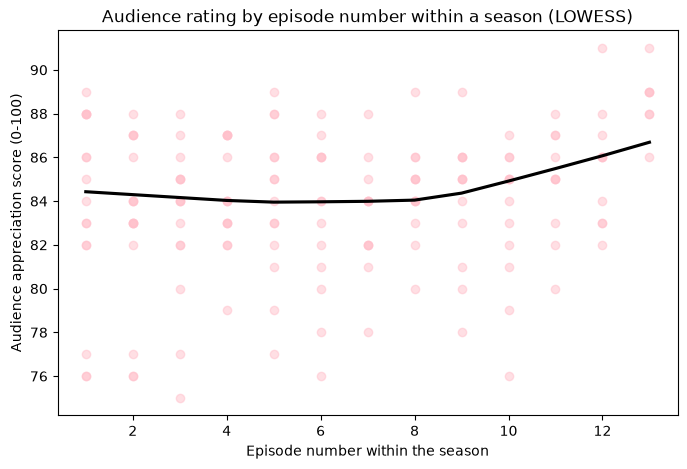

In [16]:
# Is there a relation between episode number and rating? 
# for that we can see if rating is increasing or diminishing depending on the episode number
# data visualisation

#import packages
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

#%pip install statsmodels #(for a fitted curve in the scatterplot)

#data preparation
# in order to plot relationships in R I would use a scatterplot and the LOESS method to see easy regression relations.
# Therefore I have to make a subset with dropped NA
df_plot = df.dropna(subset=['episode_number', 'rating'])

plt.figure(figsize=(8, 5))
sns.regplot(data=df_plot, x='episode_number', y='rating',
            lowess=True,                        # LOESS-style smooth curve instead of a straight line
            scatter_kws={'alpha': 0.5, 'color': 'pink'},         # see-through points, so overlapping ones show
            line_kws={'color': 'black'})
plt.title('Audience rating by episode number within a season (LOWESS)')
plt.xlabel('Episode number within the season')
plt.ylabel('Audience appreciation score (0-100)')
plt.show()






**Interpretation (9pt)**: In max. 200 words, answer your question through your visualisation. Then explain why you chose this type of plot and not [another one](https://matplotlib.org/stable/plot_types/index.html), and critically reflect on what your graph does and does not allow you to answer.

I think first and foremost since I imputed data for ``rating'' it is not the best column to plot or set in relation to something else. Also it doesn't show any interactions. Simple correlation can be seen in random generated numbers in a csv without any meaning. Therefore additional inferences like two way ANOVAs are necessary.

## Exercise 3 (20pt): The *Hidden Harbours* campaign

You work for the city museum. For one week, the museum promoted its new exhibition *Hidden Harbours* on social media with the hashtag `#HiddenHarbours`. Your file `exhibition_posts.csv` contains posts about the exhibition. The columns are:

* `post_id` - a unique number for each post
* `account` - the account that posted
* `timestamp` - date and time of the post
* `text` - the text of the post, with hashtags
* `likes`, `shares`, `comments` - reactions to the post
* `views` - how often the post was seen

Answer the questions below with pandas and `matplotlib` or `seaborn`. Write your answers in the text cells (max. 50 words per question unless stated otherwise).

**Data loading and cleaning (3pt)**

1. Load `exhibition_posts.csv` into a DataFrame. Then show the first 5 rows and use `.info()`.
2. Remove the posts without text.
3. Fill the missing values in `shares` with 0.
4. Convert `timestamp` to a datetime type and show `.info()` again.

In [32]:
# loading and cleaning
#1. Load head 5 and info
df_2 = pd.read_csv('exhibition_posts.csv')
print(df_2.head(5))
df_2.info()
#2. Remove posts without text
#View in csv show its columns 1049 + 1056
df_2 = df_2.dropna(subset=['text']) #drop the NAs for text
df_2[df_2.isnull().any(axis=1)].isnull()  #search all NAs (if not NA but null)
print(df_2['text'])
#3. Fill the missing values in shares with 0
imputer = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value=0) # Im using the imputer again but this time constant and value=0
df_2[['shares']] = imputer.fit_transform(df_2[['shares']])

print('value used to fill:', imputer.statistics_[0])
print('missing ratings after:', df_2['shares'].isna().sum())

df_2.isna().sum()
df_2.info()

#4. Convert timestamp to datetime type and show info()
df_2['timestamp'] = pd.to_datetime(df_2['timestamp'])
df_2['timestamp'].info()




   post_id        account            timestamp  \
0     1001     artbus_ams  2026-03-02 08:30:00   
1     1002    ams_history  2026-03-02 08:50:00   
2     1003    harbour_mia  2026-03-02 09:50:00   
3     1004  docklands_dad  2026-03-02 20:40:00   
4     1005    harbour_mia  2026-03-02 21:40:00   

                                                text  likes  shares  comments  \
0  Loved the photographs of dock workers in Hidde...     21     2.0        13   
1  Third visit to Hidden Harbours. Still finding ...    105    14.0        14   
2  Loved the photographs of dock workers in Hidde...     15     4.0         4   
3  The old harbour maps in Hidden Harbours are in...     30     8.0        13   
4  Queue was long, but Hidden Harbours made up fo...     56    13.0         8   

   views  
0    514  
1   3250  
2    456  
3   1381  
4   1618  
<class 'pandas.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------    

**Question 1 (3pt): Which post engaged its viewers most?** Calculate an engagement rate for every post as `(likes + shares + comments) / views`. Which post has the highest rate, and which account posted it? Is it also one of the most-viewed posts?

In [34]:
# Question 1
df_2['engagement_rate'] = (df_2['likes'] + df_2['comments'] + df_2['shares']) / df_2['views'] #Important: dont put the columns in a bracket [] but add them with +

columns = ['account', 'views', 'likes', 'comments', 'shares', 'engagement_rate']

display(df_2.sort_values('engagement_rate', ascending=False)[columns].head(5))   # the five highest posts for engagement rate
display(df_2.sort_values('likes', ascending = False)[columns].head(5))           # five highest posts for likes

,account,views,likes,comments,shares,engagement_rate
54,ams_history,345,89,13,15.0,0.339130
47,ams_history,1594,156,26,9.0,0.119824
46,artbus_ams,1525,120,39,11.0,0.111475
39,artbus_ams,1654,107,23,19.0,0.090085
22,docklands_dad,2167,124,42,27.0,0.089063


,account,views,likes,comments,shares,engagement_rate
51,noor_visits,4076,251,46,45.0,0.083906
34,photo_ruben,4640,241,47,63.0,0.075647
10,harbour_mia,4036,226,50,18.0,0.072844
15,lena_sketches,4948,222,30,38.0,0.058610
37,weekend_eva,3982,218,38,26.0,0.070819


**Answer:** the post by ams history has the highest engagement rate because it has the least views of the pack of posts. The Post with the most likes has a very low engagement rating because it was clicked more than 10 times more often.

**Question 2 (3pt)** Make a **line chart** of the total number of likes per day. On which date did the campaign get the most likes?

<Axes: xlabel='timestamp'>

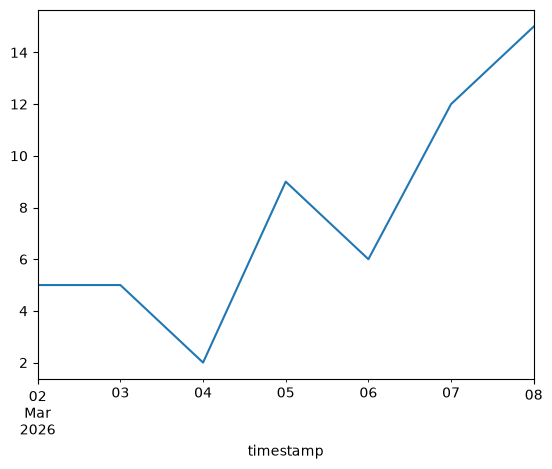

In [ ]:
# Question 2
df_2.groupby(df_2['timestamp'].dt.to_period('D')).size().plot()

# x= 'likes'
# y= df_2.groupby(df_2['timestamp'].dt.to_period('D')).size().plot()
# plt.plot(x, y, color = 'pink')
# plt.title('Likes per Day')
# plt.xlabel('likes')
# plt.ylabel('date')
# plt.show()



*Your answer*

**Question 3 (3pt)** Apart from `#HiddenHarbours`, which hashtag appears most often? Show the five most common hashtags in a **bar chart**.

In [ ]:
# Question 3
#hashtag is not a variable in csv exhibition so we have to derive them from 'text'

*Your answer*

**Question 4 (8pt): Your own question.** Formulate one question about the campaign yourself and answer it with a [plot type](https://matplotlib.org/stable/plot_types/index.html) you did not use in Questions 2 and 3. In max. 100 words, answer your question and say what these data *cannot* tell the museum.

In [9]:
# Question 4

*Your answer*

# Week 3

For Week 3, you cluster library members with k-means and reflect critically on the method. Run the next cell to load the packages.

In [41]:
#Keep cell
from sklearn.cluster import KMeans
import numpy as np

## Exercise 1 (17pt): Library members

The city library wants to understand how its members use the library. Your file `library_members.csv` (your own version) contains, for each member, their `Age` and how many fiction and non-fiction books they borrowed last year: `Fiction_Loans` and `Nonfiction_Loans`.

In the next cell, load it into a DataFrame and print the first 3 rows.

In [43]:
# load the data
df_3 = pd.read_csv('library_members.csv')
df_3.head(4)

,Age,Fiction_Loans,Nonfiction_Loans
0,66,47,41
1,63,38,37
2,54,51,9
3,27,5,7


**Question 1 (4pt): Initial exploration**
1. Make a scatter plot that shows the values of `Fiction_Loans` on the x-axis and of `Nonfiction_Loans` on the y-axis.
2. Make a histogram for each of the two loan columns.
3. In a text cell, write: how many groups of members do you see, and how can you tell?

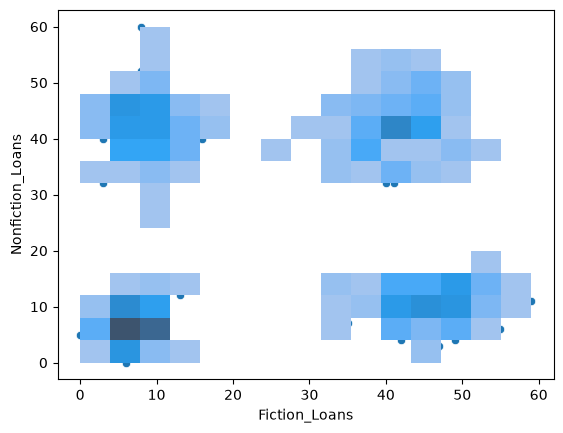

In [58]:
# Initial exploration
plot1 = sns.scatterplot(x= 'Fiction_Loans', y= 'Nonfiction_Loans', data= df_3)
plot2 = sns.histplot(x= 'Fiction_Loans', y= 'Nonfiction_Loans', data= df_3, bins= 15)

Seems like there are 4 clusters of people, because the distributions are clearly separated and centered around four 

**Question 2 (4pt): How many clusters?**
1. Use the elbow method from the Week 3 workshop. For k = 1 to 8, fit `KMeans(n_clusters=k, random_state=42, n_init=10)` on the two loan columns and plot the inertia against k.
2. Fit k-means with the 'best' k from the elbow method (again with `random_state=42, n_init=10`), store the labels in a new column `Cluster`, and make the scatter plot of Question 1 again, coloured by cluster.

<Axes: xlabel='Fiction_Loans', ylabel='Nonfiction_Loans'>

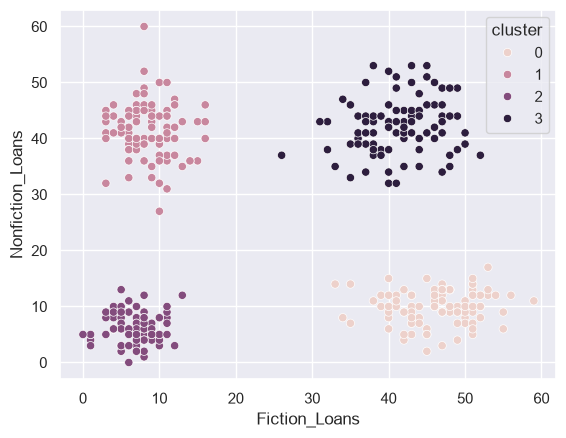

In [66]:
# Elbow method and k-means
#1. define and plot the elbow
max_k = 8
sse = []

for k in range(1, max_k):
    kmeans_ = KMeans(n_clusters = k, random_state=42, n_init=10)
    kmeans_.fit(df_3)
    sse.append(kmeans_.inertia_)

#plot the Ellbow

sns.set(style='darkgrid')

elbow_df_3  = pd.DataFrame(list(zip(range(1, max_k), sse)),
              columns = ['Number of Clusters', 'SSE'])


#sns.lineplot(x = 'Number of Clusters', y = 'SSE', data = elbow_df_3)

#It converges at 4 clusters!
#2. Fit kMeans with the optimal K
kmeans = KMeans(n_clusters = 4, random_state= 42, n_init=10)
kmeans.fit(df_3)
#add data to df:
df_3['cluster'] = np.array(kmeans.labels_)
#plot the scatter again but coloured after labels
sns.scatterplot(data = df_3, x='Fiction_Loans', y='Nonfiction_Loans', hue='cluster')




**Question 3 (9pt): Profile the clusters**
1. For each cluster, calculate the average `Age`, `Fiction_Loans` and `Nonfiction_Loans`.
2. Add a column `Persona` with self-devised names for each cluster (e.g. "Fiction fans"). (*Hint: a dictionary such as `{0: 'Fiction fans', 1: '...'}` and `.map()` turn cluster numbers into names.*)
3. In max. 150 words: describe the personas. Does age relate to the clusters? Give one reason to be careful with the names you've chosen.

In [ ]:
# Profile the clusters
#calculate mean Age, FL, NL for every cluster
df_3.groupby('cluster')[['Age', 'Fiction_Loans', 'Nonfiction_Loans']].mean()
#add column persona
df_3['persona'] = 

,Age,Fiction_Loans,Nonfiction_Loans
cluster,,,
0,48.631579,46.357895,9.947368
1,33.372340,8.606383,41.489362
2,22.021277,6.702128,6.095745
3,64.202128,41.531915,42.234043


*Your answer*

## Exercise 2 (25pt): Critical reflection

The library considers using your k-means clusters to send different newsletters to each group and to decide which books to buy.

In about 400 words, critically reflect on using k-means for these purposes. Discuss **technical** complications as well as **ethical and social** ones. Refer to at least **two readings from the course** (from either Critical Perspectives or CDA).

**Reflection:**
Decompartmentalisation or pigeonholing is a very common strategy to deal with over-complexity but often ignores hidden states that might be very important for decision making. Buying behavior e.g. is strongly affected by a lot of (changing) variables that the superficial data set is not able to cover. In this case filter bubbles are applied to cluster people based on their behavior in the past. But who can tell if they want to be in that kind of cluster? The same thing applies for other recommendation engines as news e.g. is also spread more precise to people that might be interested in them. This might be working in non complex system like the US 2 party system, but the same strategies applied to a more complex system like the german one fail. (Time series) Predictions can be very helpful for example for weather forecasting but when we deal with humans it should be treated carefully. Newer machine learning algorithms use vast amount of human brain data to predict what people might like or not (fRMI scans like Metas TribeV2) and use this to predict responsiveness to ads on social media for example. Using this as one of many layers with the caveat that those systems are never deterministic but rather 

# GenAI Disclosure and responsibility
Include a brief GenAI disclosure here, irrespective of whether you used GenAI or not.

State which tool and model you used, where known; what you used it for; and how you checked and used its output. Identify code sections developed with AI assistance. A full prompt transcript is not required unless the assignment specifies otherwise.

See [Canvas for more elaborate instructions](https://canvas.uva.nl/courses/61929).


*Write your GenAI disclosure here*

# Question for Research Masters students

This question counts for 20% of the overall mark. The rest of the marks are adjusted accordingly.

**Your task:** Since 2018, social media platforms have increasingly closed or restricted researchers' access to their data. Bruns (2019) called this the 'APIcalypse'. Choose one case (for example the end of free access to the X/Twitter API in 2023, Reddit's API pricing in 2023, or Meta's closure of CrowdTangle in 2024) and critically analyse how these changes redistribute access to cultural data and the power to produce knowledge from it. Consider the implications for using these data to train large language models (LLMs), independently scrutinising AI systems, and using those systems in research. Discuss what researchers can do instead, and at what cost.

Your analysis must be supported by credible sources. Use no more than 500 words.